<a href="https://colab.research.google.com/github/mohamedrafat9/DL/blob/main/airline_delay_cause.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import opendatasets as od


In [2]:
# Dataset downloaded locally for this workspace.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
data=pd.read_csv("airline-delay-cause-dataset/Airline_Delay_Cause.csv")
data

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2022,5,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",136.0,7.0,5.95,0.00,...,0.0,1.00,0.0,0.0,255.0,222.0,0.0,4.0,0.0,29.0
1,2022,5,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",91.0,16.0,7.38,0.00,...,0.0,6.09,0.0,0.0,884.0,351.0,0.0,81.0,0.0,452.0
2,2022,5,9E,Endeavor Air Inc.,ACK,"Nantucket, MA: Nantucket Memorial",19.0,2.0,0.13,0.00,...,0.0,0.88,1.0,0.0,138.0,4.0,0.0,106.0,0.0,28.0
3,2022,5,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",88.0,14.0,7.26,0.76,...,0.0,1.64,0.0,0.0,947.0,585.0,35.0,125.0,0.0,202.0
4,2022,5,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",181.0,19.0,13.84,0.00,...,0.0,2.09,0.0,0.0,808.0,662.0,0.0,87.0,0.0,59.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318012,2003,6,DL,Delta Air Lines Inc.,SEA,"Seattle, WA: Seattle/Tacoma International",480.0,84.0,25.69,3.09,...,0.0,21.26,0.0,0.0,3744.0,978.0,164.0,1023.0,0.0,1579.0
318013,2003,6,DL,Delta Air Lines Inc.,SFO,"San Francisco, CA: San Francisco International",505.0,111.0,21.78,2.24,...,0.0,13.17,3.0,0.0,4284.0,1376.0,138.0,2132.0,0.0,638.0
318014,2003,6,DL,Delta Air Lines Inc.,SJC,"San Jose, CA: Norman Y. Mineta San Jose Intern...",146.0,36.0,6.99,0.00,...,0.0,2.15,0.0,0.0,896.0,205.0,0.0,607.0,0.0,84.0
318015,2003,6,DL,Delta Air Lines Inc.,SJU,"San Juan, PR: Luis Munoz Marin International",95.0,13.0,3.66,0.00,...,0.0,1.42,0.0,0.0,367.0,120.0,0.0,210.0,0.0,37.0


In [5]:
print(data.shape)
data.info()

(318017, 21)
<class 'pandas.DataFrame'>
RangeIndex: 318017 entries, 0 to 318016
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year                 318017 non-null  int64  
 1   month                318017 non-null  int64  
 2   carrier              318013 non-null  str    
 3   carrier_name         318013 non-null  str    
 4   airport              318014 non-null  str    
 5   airport_name         318017 non-null  str    
 6   arr_flights          317524 non-null  float64
 7   arr_del15            317285 non-null  float64
 8   carrier_ct           317525 non-null  float64
 9   weather_ct           317523 non-null  float64
 10  nas_ct               317529 non-null  float64
 11  security_ct          317529 non-null  float64
 12  late_aircraft_ct     317529 non-null  float64
 13  arr_cancelled        317529 non-null  float64
 14  arr_diverted         317527 non-null  float64
 15  arr_delay      

In [6]:
# print(data['carrier'].value_counts().unique())
# print(data['carrier_name'].value_counts().unique())
# print(data['airport'].value_counts().unique())
print(data['airport_name'].value_counts().unique())


[3022 2990 2978 2967 2951 2937 2934 2932 2919 2914 2899 2898 2890 2865
 2859 2850 2842 2807 2736 2707 2704 2690 2686 2677 2672 2636 2626 2622
 2609 2600 2581 2566 2557 2547 2486 2468 2460 2458 2380 2371 2343 2332
 2301 2300 2265 2242 2207 2203 2176 2111 2103 2099 2071 2067 2039 2038
 2025 2017 1986 1980 1962 1955 1916 1882 1880 1858 1847 1838 1769 1757
 1744 1689 1648 1628 1618 1605 1600 1597 1530 1526 1518 1516 1478 1455
 1443 1440 1413 1402 1390 1362 1361 1340 1333 1324 1310 1304 1277 1263
 1234 1210 1205 1147 1125 1103 1078 1060 1053 1048 1039 1018  993  987
  977  968  956  955  934  924  911  906  904  901  900  887  876  866
  865  864  863  859  857  848  827  826  823  819  807  786  757  750
  739  724  723  711  692  685  672  657  654  650  638  624  614  607
  593  577  574  572  571  553  550  548  538  530  529  511  499  497
  494  491  490  487  482  473  470  462  460  458  440  430  422  412
  405  404  403  400  399  388  386  384  379  351  348  338  328  317
  312 

In [7]:
data.isnull().sum()

year                     0
month                    0
carrier                  4
carrier_name             4
airport                  3
airport_name             0
arr_flights            493
arr_del15              732
carrier_ct             492
weather_ct             494
nas_ct                 488
security_ct            488
late_aircraft_ct       488
arr_cancelled          488
arr_diverted           490
arr_delay              494
carrier_delay          492
weather_delay          488
nas_delay              488
security_delay         490
late_aircraft_delay    488
dtype: int64

In [8]:
data.describe(include='all')

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
count,318017.000000,318017.000000,318013,318013,318014,318017,317524.000000,317285.000000,317525.000000,317523.000000,...,317529.000000,317529.000000,317529.000000,317527.000000,317523.000000,317525.000000,317529.000000,317529.000000,317527.000000,317529.000000
unique,NaN,NaN,29,33,420,420,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,OO,SkyWest Airlines Inc.,DTW,"Detroit, MI: Detroit Metro Wayne County",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,38145,38145,3022,3022,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2012.450957,6.497844,NaN,NaN,NaN,NaN,381.766670,72.905076,21.073149,2.616407,...,0.179037,24.975734,7.207257,0.867674,4209.989113,1286.577224,220.567542,1099.516422,7.214845,1596.062993
std,5.678296,3.459423,NaN,NaN,NaN,NaN,1027.156722,198.936754,47.671580,9.968640,...,0.844834,75.275223,37.216301,3.915772,12519.021012,3515.417309,861.521440,4636.475908,38.854685,4924.950687
min,2003.000000,1.000000,NaN,NaN,NaN,NaN,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-19.000000,0.000000,0.000000
25%,2007.000000,3.000000,NaN,NaN,NaN,NaN,59.000000,9.000000,3.000000,0.000000,...,0.000000,1.640000,0.000000,0.000000,436.000000,148.000000,0.000000,56.000000,0.000000,79.000000
50%,2012.000000,6.000000,NaN,NaN,NaN,NaN,120.000000,23.000000,8.190000,0.580000,...,0.000000,5.860000,1.000000,0.000000,1201.000000,437.000000,25.000000,203.000000,0.000000,351.000000
75%,2018.000000,10.000000,NaN,NaN,NaN,NaN,273.000000,56.000000,19.690000,2.000000,...,0.000000,17.040000,4.000000,1.000000,3080.000000,1100.000000,159.000000,602.000000,0.000000,1110.000000


In [9]:
data = data.drop(['carrier','carrier_name','airport','airport_name'],axis=1)

In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 318017 entries, 0 to 318016
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year                 318017 non-null  int64  
 1   month                318017 non-null  int64  
 2   arr_flights          317524 non-null  float64
 3   arr_del15            317285 non-null  float64
 4   carrier_ct           317525 non-null  float64
 5   weather_ct           317523 non-null  float64
 6   nas_ct               317529 non-null  float64
 7   security_ct          317529 non-null  float64
 8   late_aircraft_ct     317529 non-null  float64
 9   arr_cancelled        317529 non-null  float64
 10  arr_diverted         317527 non-null  float64
 11  arr_delay            317523 non-null  float64
 12  carrier_delay        317525 non-null  float64
 13  weather_delay        317529 non-null  float64
 14  nas_delay            317529 non-null  float64
 15  security_delay       317527 

In [11]:
data.isnull().sum()

year                     0
month                    0
arr_flights            493
arr_del15              732
carrier_ct             492
weather_ct             494
nas_ct                 488
security_ct            488
late_aircraft_ct       488
arr_cancelled          488
arr_diverted           490
arr_delay              494
carrier_delay          492
weather_delay          488
nas_delay              488
security_delay         490
late_aircraft_delay    488
dtype: int64

In [12]:
data.dropna(inplace=True)
data

/var/folders/qw/yfv60y6508q56sgdhp4hg0940000gn/T/ipykernel_47684/731352529.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.dropna(inplace=True)


,year,month,arr_flights,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2022,5,136.0,7.0,5.95,0.00,0.05,0.0,1.00,0.0,0.0,255.0,222.0,0.0,4.0,0.0,29.0
1,2022,5,91.0,16.0,7.38,0.00,2.54,0.0,6.09,0.0,0.0,884.0,351.0,0.0,81.0,0.0,452.0
2,2022,5,19.0,2.0,0.13,0.00,1.00,0.0,0.88,1.0,0.0,138.0,4.0,0.0,106.0,0.0,28.0
3,2022,5,88.0,14.0,7.26,0.76,4.35,0.0,1.64,0.0,0.0,947.0,585.0,35.0,125.0,0.0,202.0
4,2022,5,181.0,19.0,13.84,0.00,3.07,0.0,2.09,0.0,0.0,808.0,662.0,0.0,87.0,0.0,59.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318012,2003,6,480.0,84.0,25.69,3.09,33.96,0.0,21.26,0.0,0.0,3744.0,978.0,164.0,1023.0,0.0,1579.0
318013,2003,6,505.0,111.0,21.78,2.24,73.81,0.0,13.17,3.0,0.0,4284.0,1376.0,138.0,2132.0,0.0,638.0
318014,2003,6,146.0,36.0,6.99,0.00,26.85,0.0,2.15,0.0,0.0,896.0,205.0,0.0,607.0,0.0,84.0
318015,2003,6,95.0,13.0,3.66,0.00,7.92,0.0,1.42,0.0,0.0,367.0,120.0,0.0,210.0,0.0,37.0


In [13]:
data['weather_delay'].min(),data['weather_delay'].max()

(np.float64(0.0), np.float64(57707.0))

In [14]:
data['weather_delay'].describe(include='all')

/var/folders/qw/yfv60y6508q56sgdhp4hg0940000gn/T/ipykernel_47684/3762119308.py:1: Pandas4Warning: The 'include' and 'exclude' arguments are deprecated for Series.describe and will be removed in a future version. These arguments have no effect on Series and will be removed.
  data['weather_delay'].describe(include='all')


count    317268.000000
mean        220.737197
std         861.851963
min           0.000000
25%           0.000000
50%          25.000000
75%         159.000000
max       57707.000000
Name: weather_delay, dtype: float64

In [15]:
data['WDCase'] = data['weather_delay'].apply(lambda x : 1 if x >100 else 0)

In [16]:
X = data.drop(['WDCase'],axis = 1)
y =data['WDCase']

In [17]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=44,
    shuffle =True
    )

In [18]:
import tensorflow as tf
from tensorflow import keras
KerasModel = keras.models.Sequential([
                # keras.layers.Input(shape=(17)),
            keras.layers.Dense(8,  activation = 'tanh'),
            # keras.layers.Dropout(0.1),
            keras.layers.Dense(128, activation = 'relu'),
            # keras.layers.Dropout(0.3),
            keras.layers.Dense(64, activation = 'tanh'),
            keras.layers.Dense(32, activation = 'tanh'),
            keras.layers.Dropout(0.2),
            keras.layers.Dense(1, activation = 'sigmoid')
            ])

In [19]:
from tensorflow.keras.optimizers import AdamW
MyOptimizer = AdamW(
    learning_rate=0.001,
    weight_decay=0.004,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-07,
    amsgrad=False,
    clipnorm=None,
    clipvalue=None,
    global_clipnorm=None,
    use_ema=False,
    ema_momentum=0.99,
    ema_overwrite_frequency=None,
    # jit_compile=True,
    name="AdamW")

In [20]:
print(tf.__version__)

2.21.0


In [21]:
KerasModel.compile(optimizer =MyOptimizer,
                   loss='binary_crossentropy',
                   metrics=['accuracy'],
                   jit_compile=True
                   )

In [22]:
history = KerasModel.fit(X_train,y_train,
                         validation_data=(X_test,y_test),
                         epochs=100,
                         batch_size=10000,
                         verbose=1,
                         callbacks=[tf.keras.callbacks.EarlyStopping(
                                            patience=10,
                                            monitor='val_accuracy',#"val_loss",
                                            restore_best_weights=True)])

Epoch 1/100


I0000 00:00:1793899995.735587  239024 service.cc:153] XLA service 0x7a1364be00 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793899995.735606  239024 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1793899995.806265  239024 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


W0000 00:00:1793899996.276303  239133 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.
I0000 00:00:1793899996.422459  239024 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 1/24 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.3299 - loss: 0.7905

 3/24 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5064 - loss: 0.7063

 5/24 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5972 - loss: 0.6545

... (840 outputs left out)

19/24 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9988 - loss: 0.0052

21/24 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9988 - loss: 0.0054

23/24 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9987 - loss: 0.0057

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.9987 - loss: 0.0057 - val_accuracy: 0.9986 - val_loss: 0.0059


In [23]:
print(KerasModel.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,997 (136.71 KB)

 Trainable params: 11,665 (45.57 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 23,332 (91.14 KB)

None


In [24]:
KerasModel.save('KerasModel.keras')

In [25]:
NewKerasModel = keras.models.load_model('KerasModel.keras')

In [26]:
y_pred = NewKerasModel.predict(X_test)
ModelLoss, ModelAccuracy = NewKerasModel.evaluate(X_test, y_test)
print('Model Loss is {}'.format(ModelLoss))
print('Model Accuracy is {}'.format(ModelAccuracy ))

   1/2479 ━━━━━━━━━━━━━━━━━━━━ 19:48 480ms/step

 237/2479 ━━━━━━━━━━━━━━━━━━━━ 0s 212us/step   

 471/2479 ━━━━━━━━━━━━━━━━━━━━ 0s 213us/step

 707/2479 ━━━━━━━━━━━━━━━━━━━━ 0s 213us/step

 949/2479 ━━━━━━━━━━━━━━━━━━━━ 0s 211us/step

1166/2479 ━━━━━━━━━━━━━━━━━━━━ 0s 215us/step

... (22 outputs left out)

2467/2479 ━━━━━━━━━━━━━━━━━━━━ 0s 305us/step - accuracy: 0.9987 - loss: 0.0061

2479/2479 ━━━━━━━━━━━━━━━━━━━━ 0s 359us/step - accuracy: 0.9987 - loss: 0.0061

2479/2479 ━━━━━━━━━━━━━━━━━━━━ 1s 362us/step - accuracy: 0.9987 - loss: 0.0061


Model Loss is 0.00609940430149436
Model Accuracy is 0.998688817024231


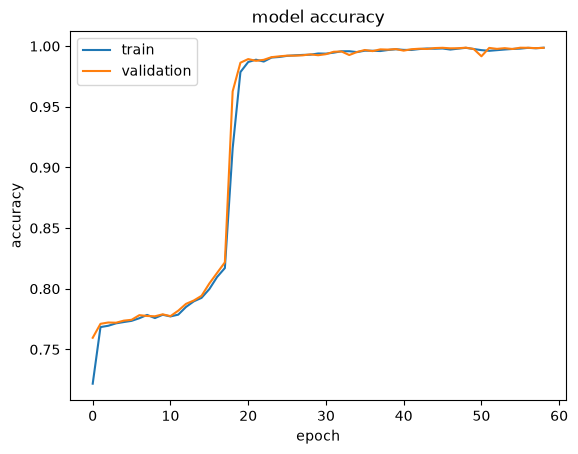

In [27]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

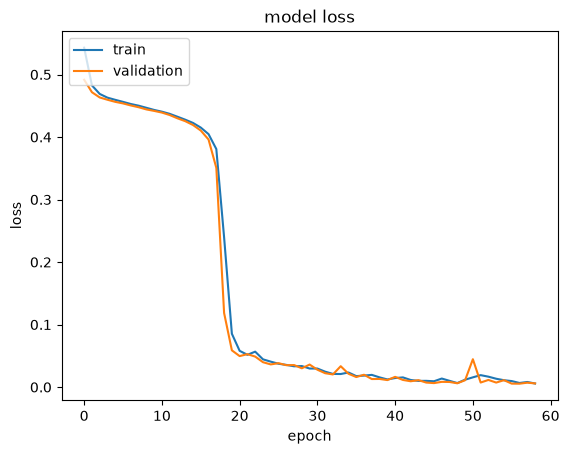

In [28]:
# "Loss"
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [29]:
y_pred=[np.round(i[0]) for i in y_pred]
y_pred

[np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float3

[[53655    69]
 [   35 25558]]


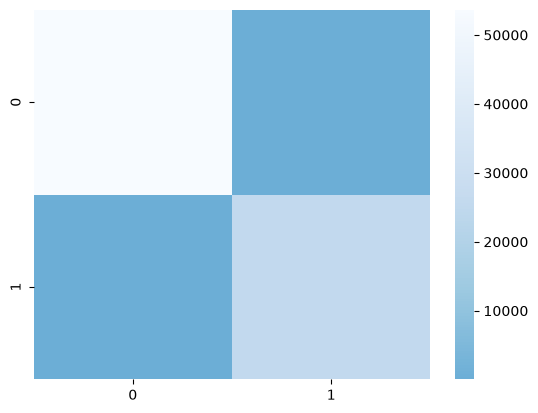

In [30]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
CM = confusion_matrix(y_test, y_pred)
print(CM)
sns.heatmap(CM, center = True,cmap='Blues_r')
plt.show()


In [31]:
from sklearn.metrics import classification_report
ClassificationReport = classification_report(y_test,y_pred)
print('Classification Report is : \n', ClassificationReport )

Classification Report is : 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     53724
           1       1.00      1.00      1.00     25593

    accuracy                           1.00     79317
   macro avg       1.00      1.00      1.00     79317
weighted avg       1.00      1.00      1.00     79317



## Executive Visual Summary

Customer-ready views of delay patterns and the weather-delay prediction model. All figures use high-resolution output and restrained, presentation-friendly styling.

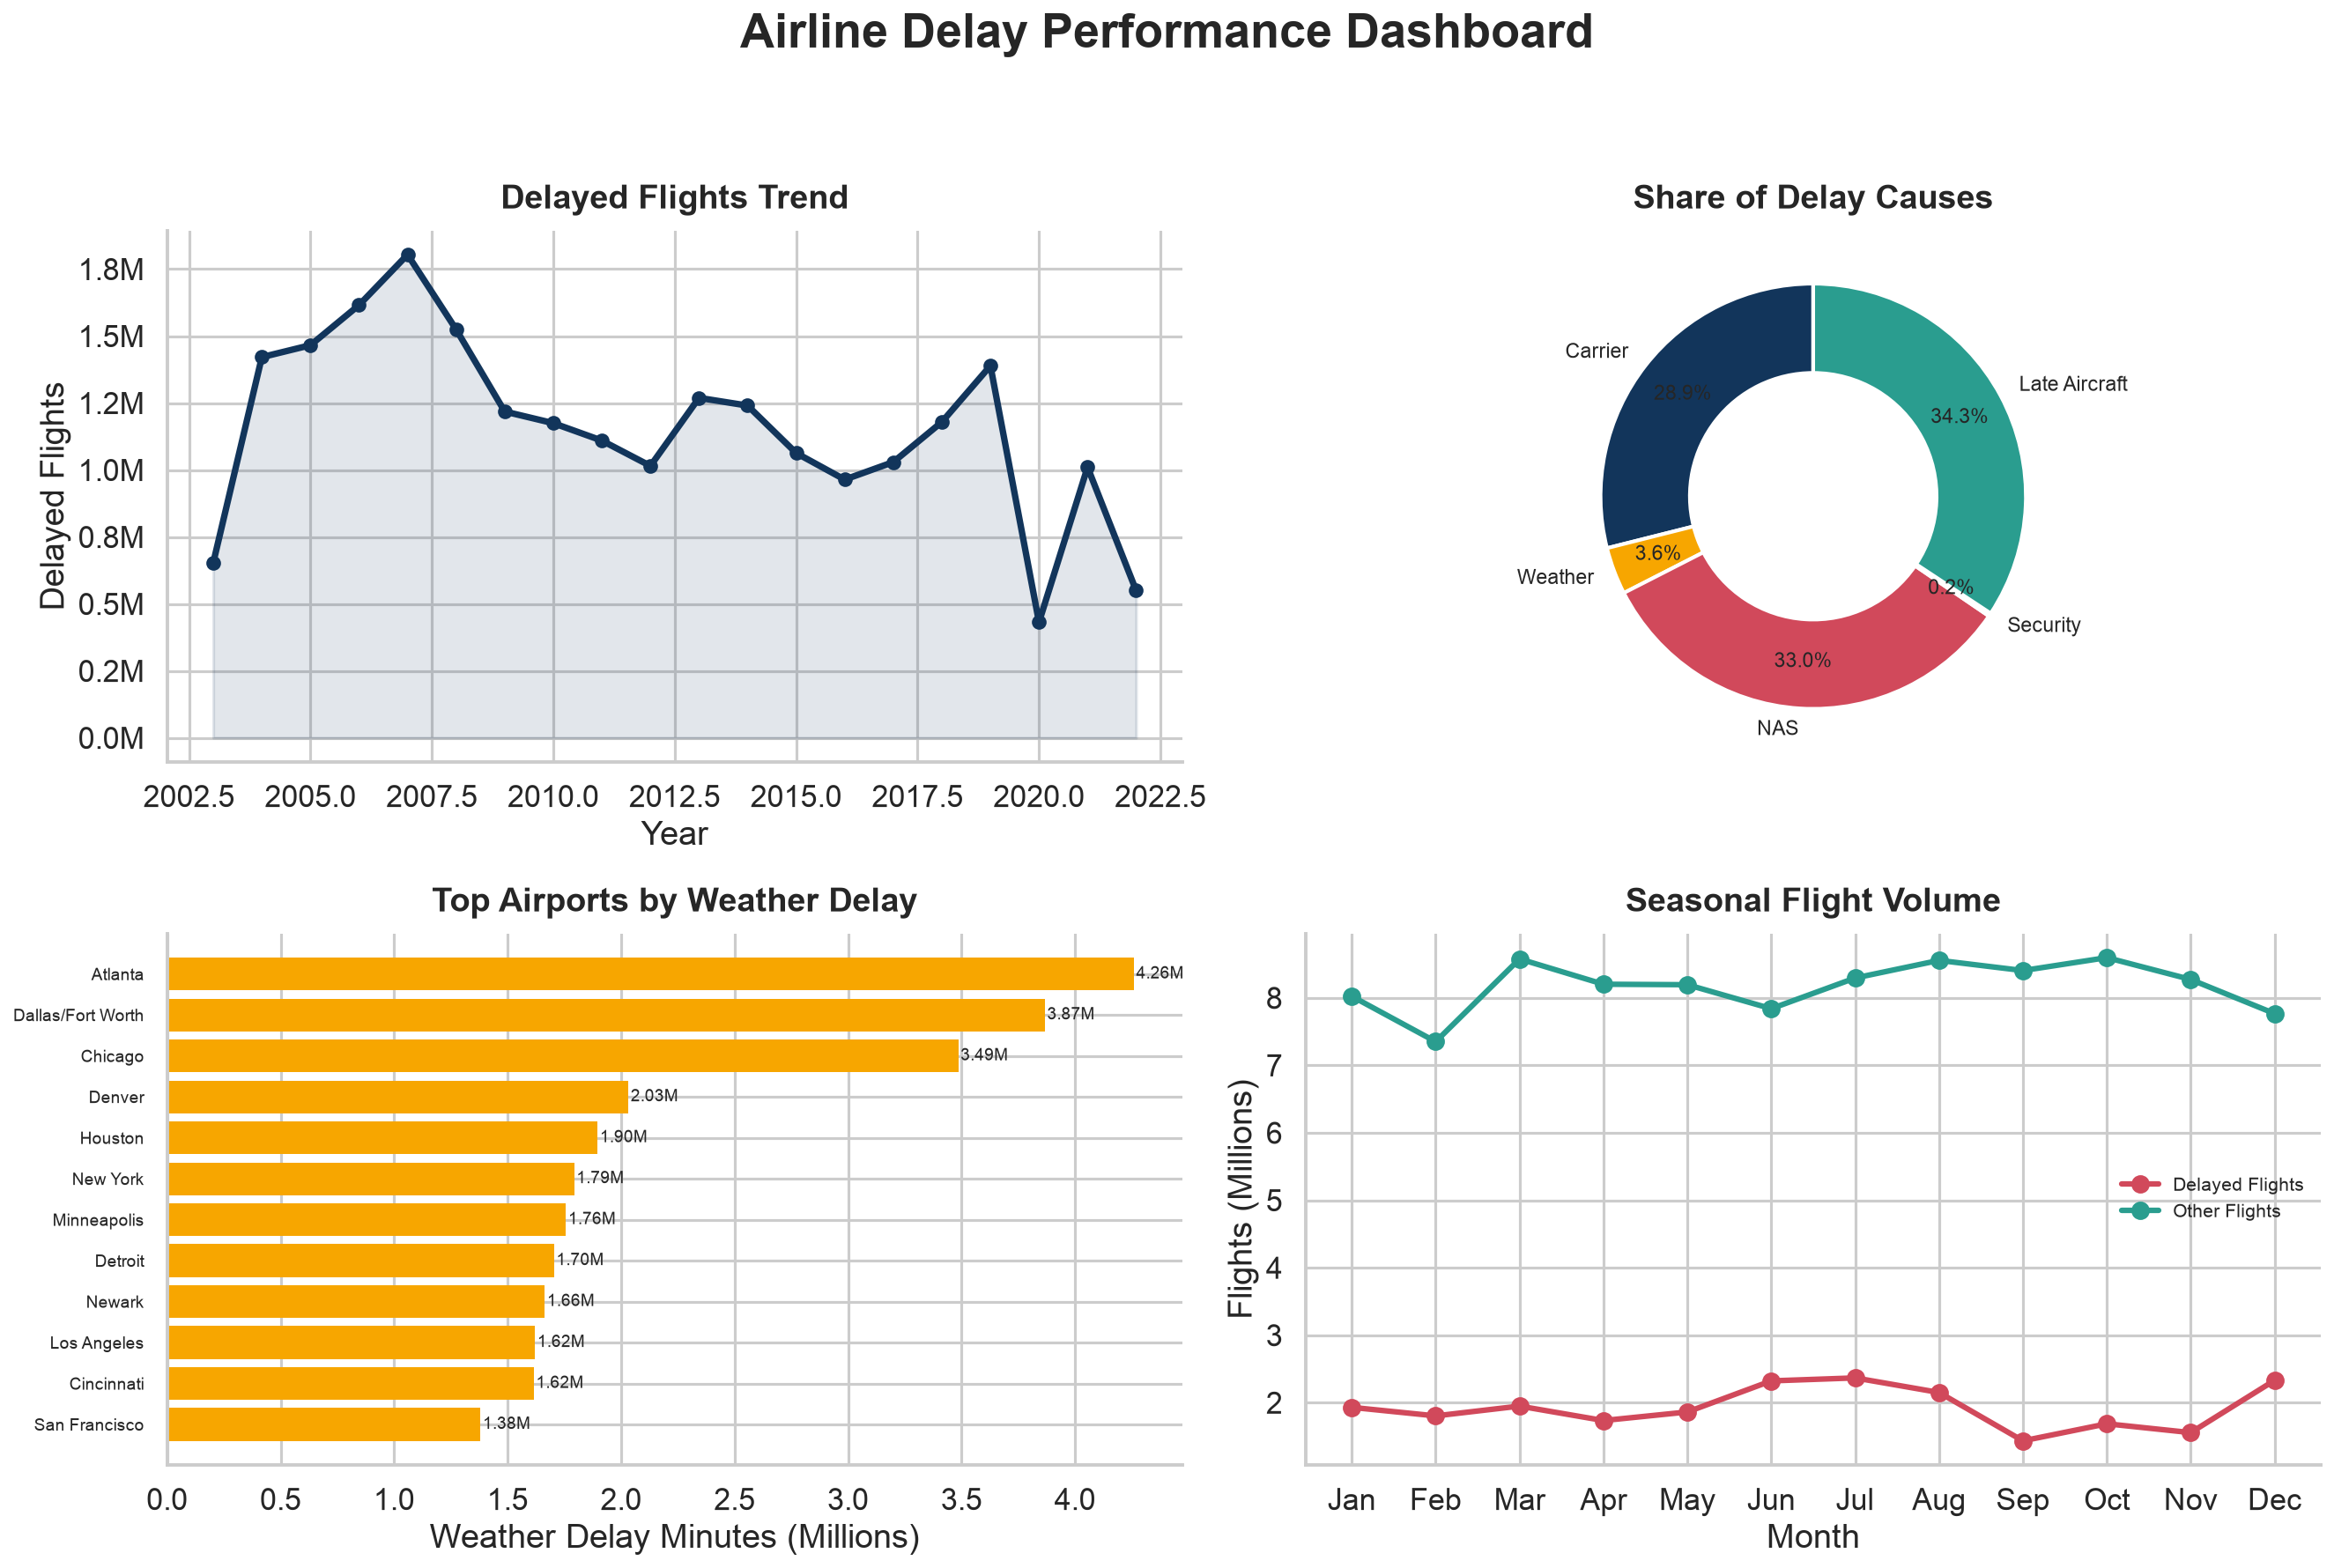

In [32]:
# Load the original data again so customer-facing dimensions are preserved
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import glob
candidates = [
    Path("airline-delay-cause-dataset/Airline_Delay_Cause.csv"),
    Path("/content/airline-delay-cause-dataset/Airline_Delay_Cause.csv")
] + [Path(p) for p in glob.glob("**/Airline_Delay_Cause.csv", recursive=True)]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError("Airline_Delay_Cause.csv was not found. Add the Kaggle dataset CSV to the notebook workspace.")
raw = pd.read_csv(csv_path)
raw = raw.dropna(subset=['arr_flights', 'arr_del15', 'carrier_ct', 'weather_ct',
                         'nas_ct', 'security_ct', 'late_aircraft_ct',
                         'arr_delay', 'carrier_delay', 'weather_delay',
                         'nas_delay', 'security_delay', 'late_aircraft_delay'])

palette = ['#12355B', '#F7A600', '#D1495B', '#7B2CBF', '#2A9D8F', '#6C757D']
sns.set_theme(style='whitegrid', context='talk')

fig, axes = plt.subplots(2, 2, figsize=(18, 12), dpi=150)
fig.suptitle('Airline Delay Performance Dashboard', fontsize=26, weight='bold', y=0.995)

# 1. Delayed flights by year
annual = raw.groupby('year')['arr_del15'].sum().astype(int)
ax = axes[0, 0]
annual.plot(ax=ax, color=palette[0], linewidth=3.5, marker='o', markersize=7)
ax.fill_between(annual.index, annual.values, alpha=0.12, color=palette[0])
ax.set_title('Delayed Flights Trend', weight='bold', pad=12)
ax.set_xlabel('Year')
ax.set_ylabel('Delayed Flights')
ax.yaxis.set_major_formatter(lambda x, pos: f'{x/1e6:.1f}M')
ax.spines[['top','right']].set_visible(False)

# 2. Delay-cause share
cause_cols = {
    'Carrier': 'carrier_ct', 'Weather': 'weather_ct', 'NAS': 'nas_ct',
    'Security': 'security_ct', 'Late Aircraft': 'late_aircraft_ct'
}
cause_totals = raw[list(cause_cols.values())].sum()
labels = list(cause_cols.keys())
colors = [palette[0], palette[1], palette[2], palette[3], palette[4]]
ax = axes[0, 1]
wedges, texts, autotexts = ax.pie(cause_totals, labels=labels, colors=colors,
                                   autopct='%1.1f%%', startangle=90,
                                   wedgeprops={'width': 0.42, 'edgecolor': 'white', 'linewidth': 2},
                                   pctdistance=0.78)
for t in texts + autotexts:
    t.set_fontsize(11)
ax.set_title('Share of Delay Causes', weight='bold', pad=12)

# 3. Top 12 airports by weather-delay minutes
weather_airports = (raw.groupby('airport_name')['weather_delay'].sum()
                    .sort_values(ascending=False).head(12)
                    .sort_values(ascending=True))
ax = axes[1, 0]
weather_airports.index = weather_airports.index.str.split(',').str[0]
y_pos = np.arange(len(weather_airports))
ax.barh(y_pos, weather_airports.values / 1e6, color=palette[1], edgecolor='none')
ax.set_yticks(y_pos, weather_airports.index, fontsize=9)
ax.set_xlabel('Weather Delay Minutes (Millions)')
ax.set_title('Top Airports by Weather Delay', weight='bold', pad=12)
ax.spines[['top','right']].set_visible(False)
for i, v in enumerate(weather_airports.values / 1e6):
    ax.text(v + 0.01, i, f'{v:.2f}M', va='center', fontsize=9)

# 4. Flights delayed versus on-time by month
monthly = raw.groupby('month').agg(delayed=('arr_del15','sum'), flights=('arr_flights','sum'))
monthly['on_time'] = monthly['flights'] - monthly['delayed']
ax = axes[1, 1]
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
ax.plot(monthly.index, monthly['delayed']/1e6, marker='o', linewidth=3,
        color=palette[2], label='Delayed Flights')
ax.plot(monthly.index, monthly['on_time']/1e6, marker='o', linewidth=3,
        color=palette[4], label='Other Flights')
ax.set_xticks(range(1,13), month_names)
ax.set_title('Seasonal Flight Volume', weight='bold', pad=12)
ax.set_xlabel('Month')
ax.set_ylabel('Flights (Millions)')
ax.legend(frameon=False, fontsize=10)
ax.spines[['top','right']].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('airline_delay_executive_dashboard.png', dpi=220, bbox_inches='tight', facecolor='white')
plt.show()


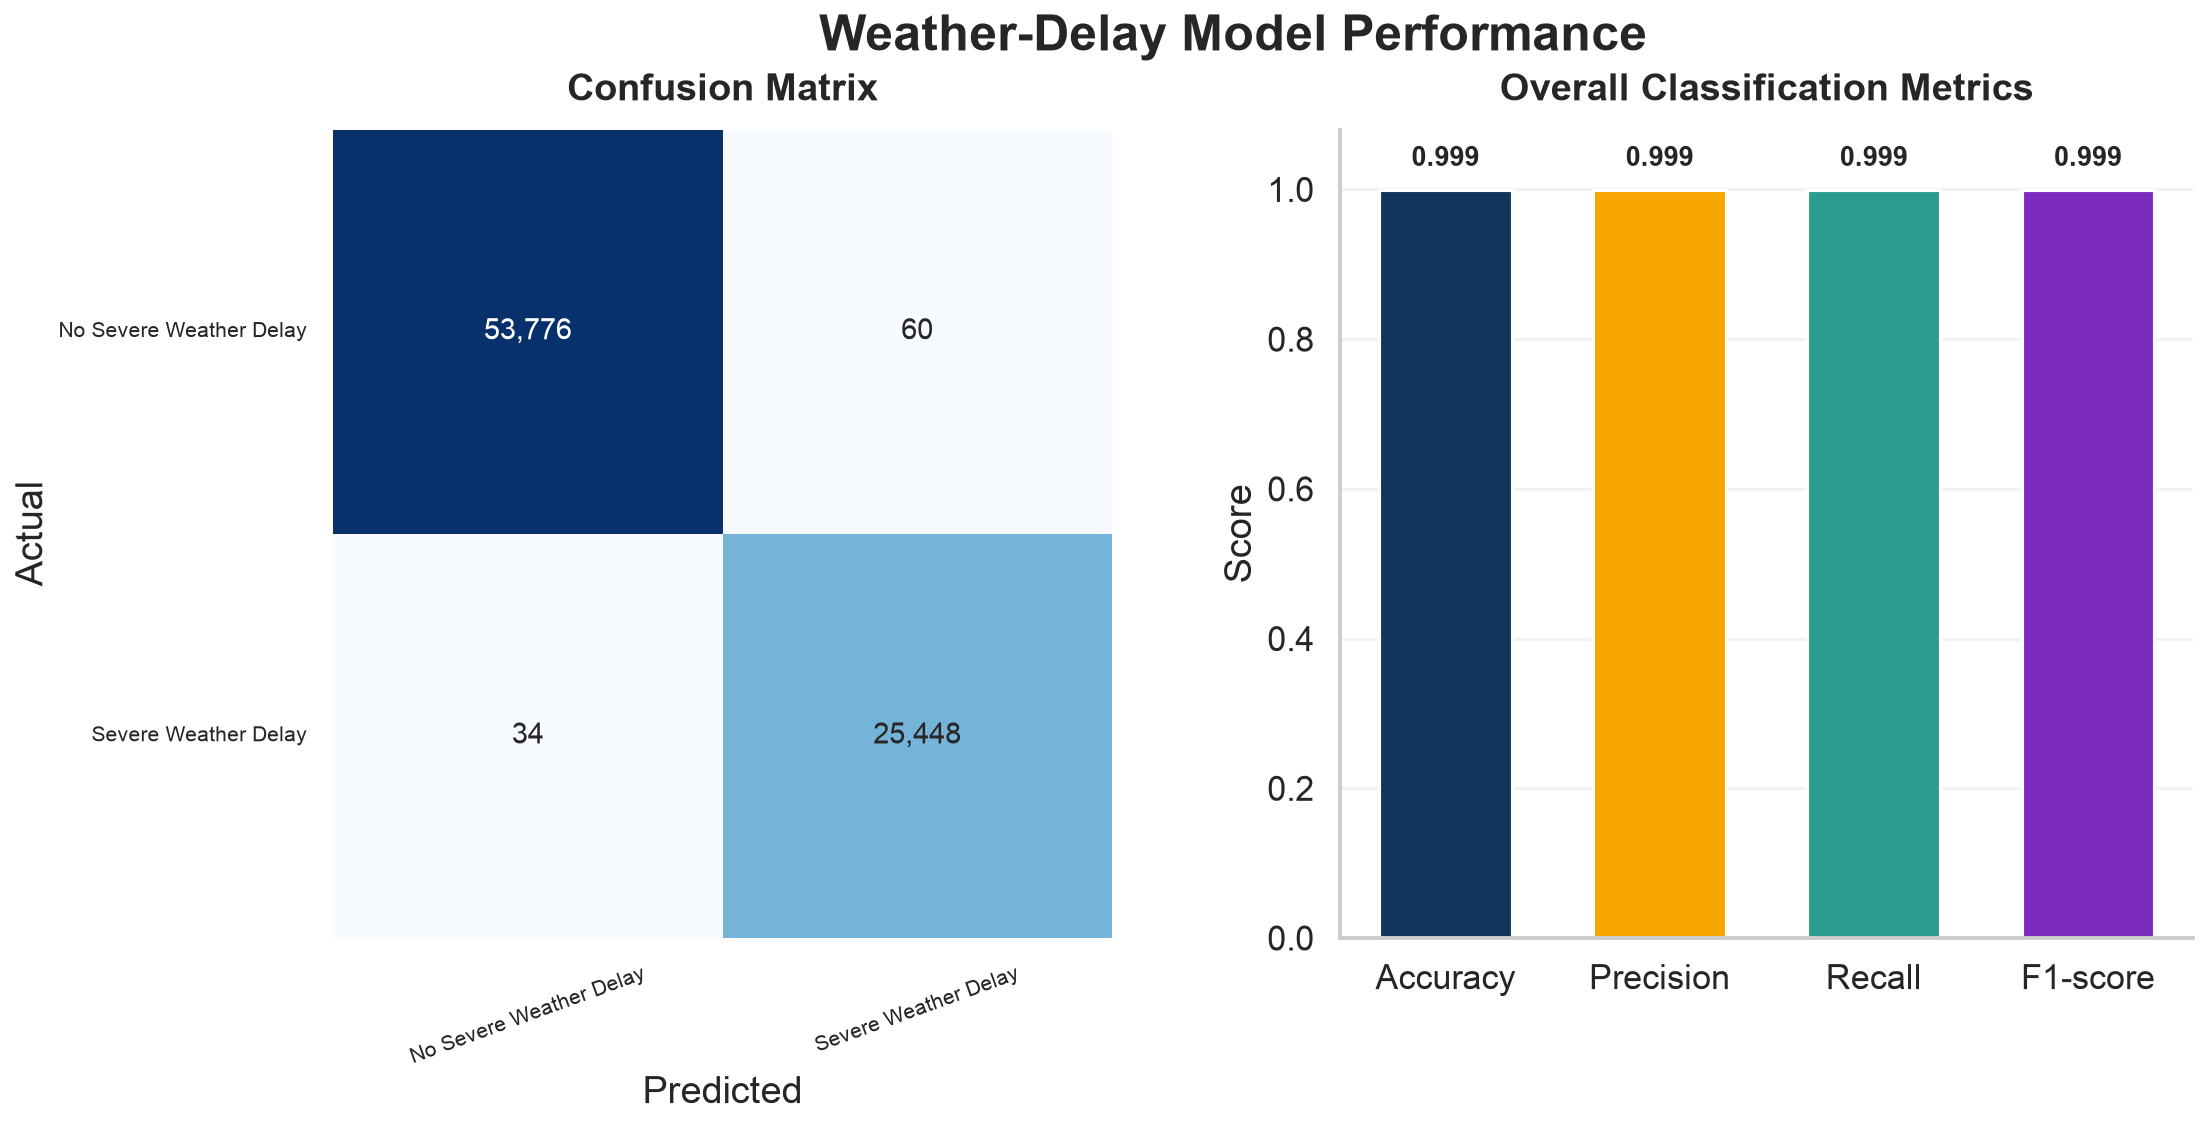

In [33]:
# Rebuild the model test set and show a clean performance dashboard
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow import keras
model_data = raw.copy()
model_data['WDCase'] = model_data['weather_delay'].apply(lambda x: 1 if x > 100 else 0)
model_features = model_data.drop(columns=['carrier','carrier_name','airport','airport_name','WDCase'], errors='ignore')
model_labels = model_data['WDCase']

X_train_model, X_test_model, y_train_model, y_test_model = train_test_split(
    model_features, model_labels, test_size=0.25, random_state=44, shuffle=True
)
loaded_model = keras.models.load_model('KerasModel.keras')
probabilities = loaded_model.predict(X_test_model, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

cm = confusion_matrix(y_test_model, predictions)
accuracy = (predictions == y_test_model).mean()
report = classification_report(y_test_model, predictions, output_dict=True)
precision = report['weighted avg']['precision']
recall = report['weighted avg']['recall']
f1 = report['weighted avg']['f1-score']

fig = plt.figure(figsize=(16, 7), dpi=150)
fig.suptitle('Weather-Delay Model Performance', fontsize=24, weight='bold', y=0.99)
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1.15], wspace=0.28)

ax1 = fig.add_subplot(gs[0])
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['No Severe Weather Delay','Severe Weather Delay'],
            yticklabels=['No Severe Weather Delay','Severe Weather Delay'], ax=ax1,
            annot_kws={'fontsize': 14})
ax1.set_title('Confusion Matrix', weight='bold', pad=14)
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')
ax1.tick_params(axis='x', rotation=20, labelsize=10)
ax1.tick_params(axis='y', rotation=0, labelsize=10)

ax2 = fig.add_subplot(gs[1])
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-score']
metric_values = [accuracy, precision, recall, f1]
bars = ax2.bar(metric_names, metric_values, color=['#12355B','#F7A600','#2A9D8F','#7B2CBF'], width=0.62)
ax2.set_ylim(0, 1.08)
ax2.set_title('Overall Classification Metrics', weight='bold', pad=14)
ax2.set_ylabel('Score')
ax2.spines[['top','right']].set_visible(False)
for bar, value in zip(bars, metric_values):
    ax2.text(bar.get_x()+bar.get_width()/2, value+0.025, f'{value:.3f}',
             ha='center', va='bottom', fontsize=13, weight='bold')
ax2.grid(axis='x', visible=False)
ax2.grid(axis='y', alpha=0.25)

plt.savefig('airline_delay_model_performance.png', dpi=220, bbox_inches='tight', facecolor='white')
plt.show()
